## Ciarra Barnett 
Intro to Predictive Modeling Lab 6 

## Part 1 


Question 1a:

The cell errors because the dataset contains missing values (NaN), and the LinearRegression model cannot handle missing values directly

Question 1b: 

The correlation plot shows mostly weak positive relationships between the variables. Age and sysBP have the strongest correlation (0.39), while cigarettes per day has very weak relationships with the other variables

Question 1c: 

The missing sysBP data is MCAR (Missing Completely at Random) because the notebook randomly removes 80% of the values without considering other variables or blood pressure values

Question 1d: 

Removing 80% of the sysBP values leaves less data, making the coefficients less accurate and the confidence intervals wider. This means the estimates are more uncertain

Question 1e: 

We use the mean from the remaining data because it represents what we actually have. Using the original dataset would include information we wouldn't normally know when data is missing

## Part 2

In [40]:
import os

print(os.getcwd())
print(os.listdir())


/Users/ciarrabarn/DS6021_F26
['uu_kde', '.DS_Store', 'requirements.txt', 'uv.lock', 'environment.yml', 'Lab 5.ipynb', 'pyproject.toml', 'refresh-env-files.sh', 'README.md', 'Lab2.ipynb', '.gitignore', 'homework', '.python-version', 'Lab 5.html', 'Lab 5.pdf', '.git', 'Lab1.ipynb', 'data', 'in_class_notebooks']


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV, lasso_path
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


auto = pd.read_csv("data/Auto.csv", na_values="?").dropna().reset_index(drop=True)

num = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[num]
y = auto["mpg"]

SEED = 200
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
alphas = np.logspace(-3, 3, 100)

auto.shape


(392, 9)

In [38]:
model1 = make_pipeline(StandardScaler(), LinearRegression())
model1.fit(X, y)

features2 = ["horsepower", "weight", "year"]
X2 = auto[features2]

model2 = make_pipeline(StandardScaler(), LinearRegression())
model2.fit(X2, y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['horsepower','weight','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [12]:
coef1 = model1.named_steps["linearregression"].coef_
coef2 = model2.named_steps["linearregression"].coef_

coef_table = pd.DataFrame(index=num)

coef_table["OLS (All Features)"] = coef1
coef_table["OLS (3 Features)"] = pd.Series(coef2, index=features2)

coef_table.round(4)


,OLS (All Features),OLS (3 Features)
displacement,0.2907,NaN
horsepower,0.0392,-0.1922
weight,-5.8312,-5.4697
acceleration,0.2489,NaN
year,2.7744,2.7545


Ridge Regresion 

In [39]:

ridge_model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=cv)
)
ridge_model.fit(X, y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridgecv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['displacement','horsepower','weight','acceleration','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [43]:
ridge_alpha = ridge_model.named_steps["ridgecv"].alpha_

print("Best Ridge Alpha:", ridge_alpha)

ridge_coef = ridge_model.named_steps["ridgecv"].coef_

coef_table["Ridge"] = ridge_coef

coef_table.round(4)


Best Ridge Alpha: 1.232846739442066


,OLS (All Features),OLS (3 Features),Lasso,ElasticNet,Ridge
displacement,0.2907,NaN,-0.0000,-0.0000,0.1473
horsepower,0.0392,-0.1922,-0.0000,-0.0000,-0.0444
weight,-5.8312,-5.4697,-5.5324,-5.5324,-5.6340
acceleration,0.2489,NaN,0.1542,0.1542,0.2011
year,2.7744,2.7545,2.7207,2.7207,2.7527


In [11]:
coef_table["Difference"] = abs(
    coef_table["OLS (All Features)"] - coef_table["Ridge"]
)

coef_table["Difference"].sort_values(ascending=False)


weight          0.197203
displacement    0.143454
horsepower      0.083567
acceleration    0.047738
year            0.021690
Name: Difference, dtype: float64

No, none of the Ridge coefficients are exactly zero. Weight changed the most, followed by displacement and horsepower. Ridge reduces coefficient sizes to help control overfitting.

Lasso Regression 

In [16]:
lasso_model = make_pipeline(
    StandardScaler(),
    LassoCV(alphas=alphas, cv=cv, max_iter=100000)
)

lasso_model.fit(X, y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lassocv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['displacement','horsepower','weight','acceleration','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [14]:
lasso_alpha = lasso_model.named_steps["lassocv"].alpha_

print("Best Lasso Alpha:", lasso_alpha)

lasso_coef = lasso_model.named_steps["lassocv"].coef_

coef_table["Lasso"] = lasso_coef

coef_table.round(4)


Best Lasso Alpha: 0.049770235643321115


,OLS (All Features),OLS (3 Features),Lasso
displacement,0.2907,NaN,-0.0000
horsepower,0.0392,-0.1922,-0.0000
weight,-5.8312,-5.4697,-5.5324
acceleration,0.2489,NaN,0.1542
year,2.7744,2.7545,2.7207


Lasso selected an alpha of 0.0498 and dropped displacement and horsepower because their coefficients became zero. It kept weight, acceleration, and year.

In [15]:
dropped_features = coef_table.index[
    np.isclose(coef_table["Lasso"], 0, atol=1e-10)
].tolist()

print("Dropped features:", dropped_features)


Dropped features: ['displacement', 'horsepower']


Lasso may be more reliable because it uses cross-validation and reduces overfitting by shrinking coefficients. However, it can remove useful predictors, especially when variables are highly correlated.

ElasticNet Regression: 

In [17]:
elastic_model = make_pipeline(
    StandardScaler(),
    ElasticNetCV(
        alphas=alphas,
        l1_ratio=[0.1, 0.5, 0.9, 1],
        cv=cv,
        max_iter=100000
    )
)

elastic_model.fit(X, y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('elasticnetcv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['displacement','horsepower','weight','acceleration','year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [18]:
elastic_alpha = elastic_model.named_steps["elasticnetcv"].alpha_
elastic_ratio = elastic_model.named_steps["elasticnetcv"].l1_ratio_

print("Best ElasticNet Alpha:", elastic_alpha)
print("Best L1 Ratio:", elastic_ratio)

elastic_coef = elastic_model.named_steps["elasticnetcv"].coef_

coef_table["ElasticNet"] = elastic_coef

coef_table.round(4)


Best ElasticNet Alpha: 0.049770235643321115
Best L1 Ratio: 1.0


,OLS (All Features),OLS (3 Features),Lasso,ElasticNet
displacement,0.2907,NaN,-0.0000,-0.0000
horsepower,0.0392,-0.1922,-0.0000,-0.0000
weight,-5.8312,-5.4697,-5.5324,-5.5324
acceleration,0.2489,NaN,0.1542,0.1542
year,2.7744,2.7545,2.7207,2.7207


ElasticNet selected an alpha of 0.0498 and an L1 ratio of 1.0. This means the model chose pure Lasso regularization instead of a mixture of Ridge and Lasso.

In [21]:
print(coef_table.columns.tolist())

['OLS (All Features)', 'OLS (3 Features)', 'Lasso', 'ElasticNet']


In [44]:
ridge_coef = ridge_model.named_steps["ridgecv"].coef_
coef_table["Ridge"] = ridge_coef

coef_table.round(4)

,OLS (All Features),OLS (3 Features),Lasso,ElasticNet,Ridge
displacement,0.2907,NaN,-0.0000,-0.0000,0.1473
horsepower,0.0392,-0.1922,-0.0000,-0.0000,-0.0444
weight,-5.8312,-5.4697,-5.5324,-5.5324,-5.6340
acceleration,0.2489,NaN,0.1542,0.1542,0.2011
year,2.7744,2.7545,2.7207,2.7207,2.7527


Weight and year are the strongest predictors because they have large coefficients across all models. Acceleration also remains important because Lasso and ElasticNet kept it. Displacement and horsepower appear less important because both models removed them 

## Part 3 

Baseline

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

fram = pd.read_csv("data/framingham.csv").dropna()

y = fram["TenYearCHD"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(fram.shape)


(3658, 16)


In [25]:
chd_fraction = y.mean()

print("CHD Fraction:", chd_fraction)
print("CHD Percentage:", chd_fraction * 100)


CHD Fraction: 0.15226899945325315
CHD Percentage: 15.226899945325314


Approximately 15.23% which is 0.1522 of patients developed CHD within 10 years

In [26]:
y_pred = np.zeros(len(y), dtype=int)

baseline_accuracy = accuracy_score(y, y_pred)

print("Baseline Accuracy:", baseline_accuracy)


Baseline Accuracy: 0.8477310005467469


The model has an accuracy of 84.77% because most patients did not develop CHD within 10 years 

In [28]:
baseline_probs = np.full(len(y), chd_fraction)

baseline_logloss = log_loss(y, baseline_probs)

print("Baseline Log Loss:", baseline_logloss)


Baseline Log Loss: 0.4266247901946631


The baseline log loss is 0.4266 when every patient is assigned the same CHD probability of 15.23%

Fit Both Logistic Regression Models 

In [29]:

X_A = fram[["male", "age"]]

preprocess_A = ColumnTransformer([
    ("binary", "passthrough", ["male"]),
    ("numeric", StandardScaler(), ["age"])
])

model_A = Pipeline([
    ("preprocess", preprocess_A),
    ("logistic", LogisticRegression(max_iter=1000))
])

model_A.fit(X_A, y)

X_B = fram[["male", "cigsPerDay"]]

preprocess_B = ColumnTransformer([
    ("binary", "passthrough", ["male"]),
    ("numeric", StandardScaler(), ["cigsPerDay"])
])

model_B = Pipeline([
    ("preprocess", preprocess_B),
    ("logistic", LogisticRegression(max_iter=1000))
])

model_B.fit(X_B, y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['male','cigsPerDay']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('binary', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in 

I fitted two logistic regression models to predict CHD. Model A uses sex and age, while Model B uses sex and cigarettes per day

In [30]:
probs_A = model_A.predict_proba(X_A)[:, 1]
probs_B = model_B.predict_proba(X_B)[:, 1]

loss_A = log_loss(y, probs_A)
loss_B = log_loss(y, probs_B)

print("Model A Log Loss:", round(loss_A, 4))
print("Model B Log Loss:", round(loss_B, 4))


Model A Log Loss: 0.3942
Model B Log Loss: 0.4222


Model A had a log loss of 0.3942, while Model B had a log loss of 0.4222. Model A performed better because it had the lower log loss

In [31]:
manual_loss_A = -np.mean(
    y * np.log(probs_A) +
    (1 - y) * np.log(1 - probs_A)
)

print("Manual Log Loss:", round(manual_loss_A, 4))
print("Sklearn Log Loss:", round(loss_A, 4))


print("Results Match:", np.isclose(manual_loss_A, loss_A))


Manual Log Loss: 0.3942
Sklearn Log Loss: 0.3942
Results Match: True


The manual NumPy log loss was 0.3942, which matched sklearn's result. This confirms that both calculations give the same number 

Cross-Validation 

In [32]:
scoring = ["accuracy", "neg_log_loss", "roc_auc"]

cv_A = cross_validate(model_A, X_A, y, cv=cv, scoring=scoring)
cv_B = cross_validate(model_B, X_B, y, cv=cv, scoring=scoring)

results = pd.DataFrame({
    "Model A Mean": [
        cv_A["test_accuracy"].mean(),
        -cv_A["test_neg_log_loss"].mean(),
        cv_A["test_roc_auc"].mean()
    ],
    "Model A SD": [
        cv_A["test_accuracy"].std(),
        cv_A["test_neg_log_loss"].std(),
        cv_A["test_roc_auc"].std()
    ],
    "Model B Mean": [
        cv_B["test_accuracy"].mean(),
        -cv_B["test_neg_log_loss"].mean(),
        cv_B["test_roc_auc"].mean()
    ],
    "Model B SD": [
        cv_B["test_accuracy"].std(),
        cv_B["test_neg_log_loss"].std(),
        cv_B["test_roc_auc"].std()
    ]
}, index=["Accuracy", "Log Loss", "ROC AUC"])

results.round(4)


,Model A Mean,Model A SD,Model B Mean,Model B SD
Accuracy,0.8480,0.0010,0.8477,0.0006
Log Loss,0.3953,0.0134,0.4233,0.0023
ROC AUC,0.7013,0.0396,0.5645,0.0319


In [36]:
print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Model A CV Accuracy:", round(results.loc["Accuracy", "Model A Mean"], 4))
print("Model B CV Accuracy:", round(results.loc["Accuracy", "Model B Mean"], 4))

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Model A CV Accuracy:", round(results.loc["Accuracy", "Model A Mean"], 4))
print("Model B CV Accuracy:", round(results.loc["Accuracy", "Model B Mean"], 4))


Baseline Accuracy: 0.8477
Model A CV Accuracy: 0.848
Model B CV Accuracy: 0.8477
Baseline Accuracy: 0.8477
Model A CV Accuracy: 0.848
Model B CV Accuracy: 0.8477


Both models have about 84.8% accuracy, which is almost the same as the baseline accuracy of 84.77%. Accuracy is not a useful metric by itself because most patients do not develop CHD, so a model can have high accuracy while missing patients who actually develop CHD

In [34]:
cv_probs_A = cross_val_predict(
    model_A, X_A, y, cv=cv, method="predict_proba"
)[:, 1]

cv_probs_B = cross_val_predict(
    model_B, X_B, y, cv=cv, method="predict_proba"
)[:, 1]


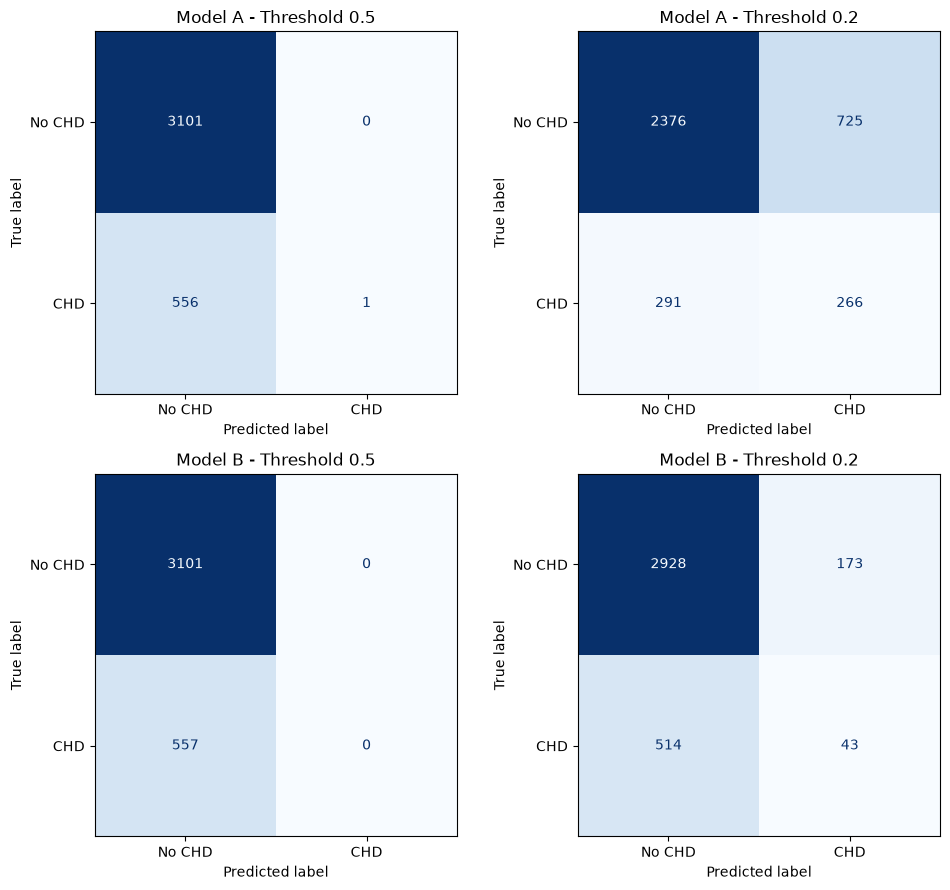

In [ ]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for i, (name, probs) in enumerate([
    ("Model A", cv_probs_A),
    ("Model B", cv_probs_B)
]):
    for j, threshold in enumerate([0.5, 0.2]):
        predictions = (probs >= threshold).astype(int)

        cm = confusion_matrix(y, predictions, labels=[0, 1])

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["No CHD", "CHD"]
        ).plot(ax=axes[i, j], colorbar=False, cmap="Blues")

        axes[i, j].set_title(f"{name} - Threshold {threshold}")

plt.tight_layout()
plt.show()


At a threshold of 0.5, both models missed almost every CHD case. Lowering the threshold to 0.2 helped identify more CHD cases, but also increased false positives. Model A identified more CHD cases than Model B 

I would choose Model A because it has a lower log loss (0.3953) and higher ROC AUC (0.7013) than Model B. It also detects more CHD cases. Model A performs better than the baseline because its log loss is lower (0.3953 vs. 0.4266), meaning its predicted probabilities are more accurate

AI Disclosure: 

I used AI to help debug syntax errors, explain parts of the notebook I did not fully understand, and assist with writing and correcting some code. I reviewed and ran the code to ensure it worked and met the lab requirements. 